# SoulIA — Sprint 4: Modelagem de Machine Learning

**Objetivo:** classificar o nível de engajamento (`baixo`, `medio`, `alto`) usando os indicadores da base sintética criada na Sprint 3. Serão comparados Decision Tree e Random Forest.

> A base contém dados sintéticos. As métricas medem o desempenho sobre essa simulação e não garantem o mesmo desempenho com usuários reais.

## 1. Bibliotecas e carregamento dos dados
O identificador `id_usuario` não será usado como atributo, pois é apenas uma chave. O rótulo é `nivel_engajamento`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
import joblib
from pathlib import Path

ARQUIVO = Path("base_soulia.csv")
df = pd.read_csv(ARQUIVO)
df.head()

,id_usuario,idade,dias_ativo,acessos,missoes_recebidas,missoes_concluidas,acoes_sustentaveis,interacoes_chatbot,comentarios,curtidas,participacoes_comunidade,streak_maximo,pontos,recompensas_resgatadas,nivel_engajamento
0,1,21,7,27,40,12,4,13,10,47,0,5,428,1,baixo
1,2,19,8,7,32,9,0,17,1,11,1,4,258,1,baixo
2,3,26,2,4,59,22,9,3,1,1,0,2,595,1,baixo
3,4,29,89,105,38,29,46,235,34,31,12,11,2048,8,medio
4,5,27,161,177,51,30,45,71,5,338,14,75,2285,1,medio


## 2. Entendimento e validação da base

In [2]:
print("Dimensões:", df.shape)
print("\nTipos e nulos:")
df.info()
print("\nDuplicidade de ID:", df["id_usuario"].duplicated().sum())
print("\nDistribuição do alvo:")
print(df["nivel_engajamento"].value_counts())
print("\nPercentual por classe:")
print((df["nivel_engajamento"].value_counts(normalize=True)*100).round(2))
print("\nEstatísticas:")
display(df.describe(include="all").T)

Dimensões: (500, 15)

Tipos e nulos:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   id_usuario                500 non-null    int64
 1   idade                     500 non-null    int64
 2   dias_ativo                500 non-null    int64
 3   acessos                   500 non-null    int64
 4   missoes_recebidas         500 non-null    int64
 5   missoes_concluidas        500 non-null    int64
 6   acoes_sustentaveis        500 non-null    int64
 7   interacoes_chatbot        500 non-null    int64
 8   comentarios               500 non-null    int64
 9   curtidas                  500 non-null    int64
 10  participacoes_comunidade  500 non-null    int64
 11  streak_maximo             500 non-null    int64
 12  pontos                    500 non-null    int64
 13  recompensas_resgatadas    500 non-null    int64
 14  nivel_engajament

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_usuario,500.0,NaN,NaN,NaN,250.5,144.481833,1.0,125.75,250.5,375.25,500.0
idade,500.0,NaN,NaN,NaN,26.872,5.174666,18.0,22.0,27.0,31.0,35.0
dias_ativo,500.0,NaN,NaN,NaN,89.564,54.429616,1.0,38.0,89.0,140.0,180.0
acessos,500.0,NaN,NaN,NaN,98.278,55.708991,1.0,46.0,96.5,150.25,200.0
missoes_recebidas,500.0,NaN,NaN,NaN,41.328,22.076666,5.0,22.0,40.0,60.0,80.0
missoes_concluidas,500.0,NaN,NaN,NaN,21.282,16.235815,1.0,9.0,17.0,30.0,75.0
acoes_sustentaveis,500.0,NaN,NaN,NaN,21.348,22.504217,0.0,6.0,14.0,30.0,119.0
interacoes_chatbot,500.0,NaN,NaN,NaN,146.288,128.262932,0.0,41.75,108.5,218.5,575.0
comentarios,500.0,NaN,NaN,NaN,24.754,21.353534,0.0,6.0,19.0,38.0,93.0
curtidas,500.0,NaN,NaN,NaN,100.99,88.126332,0.0,33.0,71.5,143.0,361.0


### Interpretação inicial
A base possui 500 registros e 15 colunas. O alvo apresenta distribuição desigual: a classe `alto` é minoritária. Por isso, além da acurácia, serão observadas precisão, recall e F1-score macro, que atribuem o mesmo peso às três classes. O identificador não entra no treinamento.

In [3]:
# Verificações de qualidade descritas na Sprint 3
assert df["id_usuario"].is_unique, "Existem IDs duplicados"
assert not df.isna().any().any(), "Existem valores ausentes"
assert (df["missoes_concluidas"] <= df["missoes_recebidas"]).all(), "Missões concluídas > recebidas"
assert (df["streak_maximo"] <= df["dias_ativo"]).all(), "Streak maior que dias ativos"
assert set(df["nivel_engajamento"].unique()) == {"baixo", "medio", "alto"}
print("Validações concluídas sem inconsistências.")

Validações concluídas sem inconsistências.


## 3. Preparação dos dados
Será utilizada uma divisão estratificada: 80% para treino e 20% para teste. A estratificação preserva aproximadamente a proporção das classes nos dois conjuntos. A idade foi mantida como variável de perfil presente na base; `id_usuario` foi removido.

In [4]:
FEATURES = [
    "idade", "dias_ativo", "acessos", "missoes_recebidas",
    "missoes_concluidas", "acoes_sustentaveis", "interacoes_chatbot",
    "comentarios", "curtidas", "participacoes_comunidade",
    "streak_maximo", "pontos", "recompensas_resgatadas"
]
ALVO = "nivel_engajamento"
X = df[FEATURES]
y = df[ALVO]
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Treino:", X_treino.shape, "Teste:", X_teste.shape)
print("Proporção no teste:")
print(y_teste.value_counts(normalize=True).round(3))

Treino: (400, 13) Teste: (100, 13)
Proporção no teste:
nivel_engajamento
medio    0.51
baixo    0.44
alto     0.05
Name: proportion, dtype: float64


## 4. Modelo 1 — Árvore de Decisão
A Árvore de Decisão é interpretável e representa regras em formato de árvore. Foi limitado o número de níveis para reduzir o risco de sobreajuste. `class_weight="balanced"` compensa parcialmente o desequilíbrio entre as classes.

In [5]:
arvore = DecisionTreeClassifier(
    max_depth=5, min_samples_leaf=4, class_weight="balanced", random_state=42
)
arvore.fit(X_treino, y_treino)
pred_arvore = arvore.predict(X_teste)
print(classification_report(y_teste, pred_arvore, zero_division=0))
print("Acurácia:", round(accuracy_score(y_teste, pred_arvore), 4))

              precision    recall  f1-score   support

        alto       0.80      0.80      0.80         5
       baixo       0.93      0.95      0.94        44
       medio       0.94      0.92      0.93        51

    accuracy                           0.93       100
   macro avg       0.89      0.89      0.89       100
weighted avg       0.93      0.93      0.93       100

Acurácia: 0.93


### Leitura dos resultados — Árvore de Decisão
No conjunto de teste (100 usuários) a árvore acertou 93. Os 7 erros ficaram na fronteira entre classes vizinhas: 2 usuários `baixo` previstos como `medio`, 3 `medio` previstos como `baixo`, 1 `medio` previsto como `alto` e 1 `alto` previsto como `medio`. As classes grandes tiveram F1 de 0,94 (`baixo`) e 0,93 (`medio`). Na classe minoritária `alto`, precisão e recall foram 0,80, ou seja, 4 acertos em apenas 5 exemplos. Como o teste tem só 5 usuários `alto`, **cada erro nessa classe muda o recall em 20 pontos percentuais**; esse número é instável e não deve ser lido como desempenho confiável.

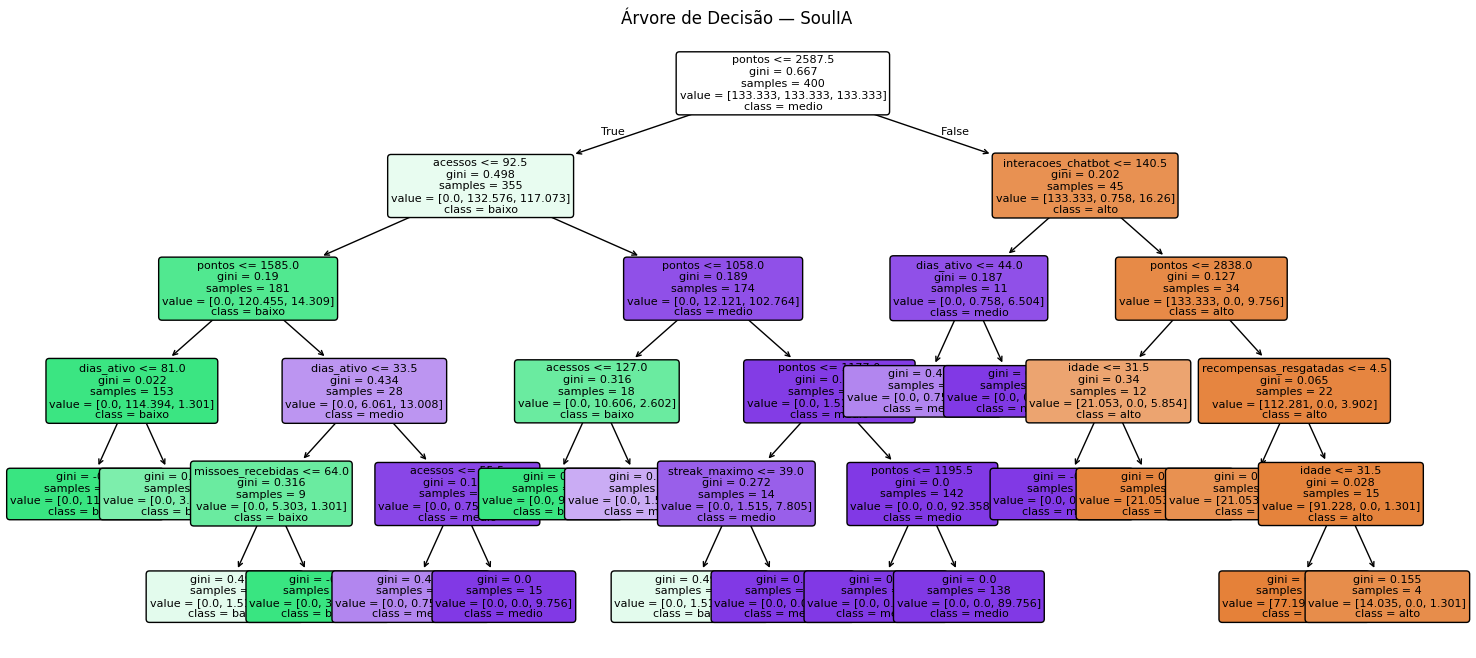

In [6]:
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(arvore, feature_names=FEATURES, class_names=arvore.classes_,
          filled=True, rounded=True, fontsize=8, ax=ax)
plt.title("Árvore de Decisão — SoulIA")
plt.show()

### Leitura da árvore
A raiz divide por `pontos` (≤ 2587,5) e, nos níveis seguintes, aparecem sobretudo `acessos` e `interacoes_chatbot`. Isso é coerente com a importância das variáveis na própria árvore: `pontos` (≈ 0,57) e `acessos` (≈ 0,32) concentram cerca de 89% da importância. A classe `alto` só é prevista quando `pontos` > 2587,5 **e** `interacoes_chatbot` > 140,5, o que faz sentido para o problema: pontuação alta combinada com muita conversa com o chatbot.

Um ponto de atenção: em uma das folhas, a árvore usa `idade` (≤ 31,5) para separar `medio` de `alto` entre usuários com pontos entre 2587,5 e 2838. Idade não deveria determinar nível de engajamento; com apenas 19 exemplos `alto` no treino, isso provavelmente é um ajuste a ruído da amostra, e não uma regra real. É um exemplo concreto de como uma árvore pode memorizar detalhes de poucos casos.

## 5. Modelo 2 — Random Forest
Random Forest combina várias árvores treinadas com amostras e subconjuntos de atributos. A combinação tende a reduzir a variância de uma árvore isolada. Foi utilizada ponderação de classes para lidar com a classe minoritária.

In [7]:
floresta = RandomForestClassifier(
    n_estimators=300, max_features="sqrt", min_samples_leaf=2,
    class_weight="balanced_subsample", random_state=42, n_jobs=-1
)
floresta.fit(X_treino, y_treino)
pred_floresta = floresta.predict(X_teste)
print(classification_report(y_teste, pred_floresta, zero_division=0))
print("Acurácia:", round(accuracy_score(y_teste, pred_floresta), 4))

              precision    recall  f1-score   support

        alto       0.75      0.60      0.67         5
       baixo       0.96      0.98      0.97        44
       medio       0.94      0.94      0.94        51

    accuracy                           0.94       100
   macro avg       0.88      0.84      0.86       100
weighted avg       0.94      0.94      0.94       100

Acurácia: 0.94


### Leitura dos resultados — Random Forest
A floresta acertou 94 dos 100 usuários do teste, um acerto a mais que a árvore. O ganho veio das classes grandes: `baixo` com recall de 0,98 e `medio` com F1 de 0,94. Na classe `alto`, porém, o resultado foi pior: apenas 3 dos 5 usuários foram identificados (recall 0,60), e os outros 2 foram classificados como `medio`. Ou seja, a floresta ficou mais "conservadora" com a classe minoritária, apesar do `class_weight="balanced_subsample"`.

## 6. Comparação dos modelos
A acurácia mede a proporção total de acertos. Precisão macro, recall macro e F1 macro calculam a métrica por classe e depois fazem a média simples. O F1 macro é especialmente relevante porque a classe `alto` tem poucos exemplos.

In [8]:
def calcular_metricas(nome, real, previsto):
    return {
        "Modelo": nome,
        "Acurácia": accuracy_score(real, previsto),
        "Precisão (macro)": precision_score(real, previsto, average="macro", zero_division=0),
        "Recall (macro)": recall_score(real, previsto, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(real, previsto, average="macro", zero_division=0)
    }
comparacao = pd.DataFrame([
    calcular_metricas("Decision Tree", y_teste, pred_arvore),
    calcular_metricas("Random Forest", y_teste, pred_floresta)
]).set_index("Modelo")
display(comparacao.round(4))

,Acurácia,Precisão (macro),Recall (macro),F1-score (macro)
Modelo,,,,
Decision Tree,0.93,0.8911,0.8920,0.8915
Random Forest,0.94,0.8822,0.8395,0.8580


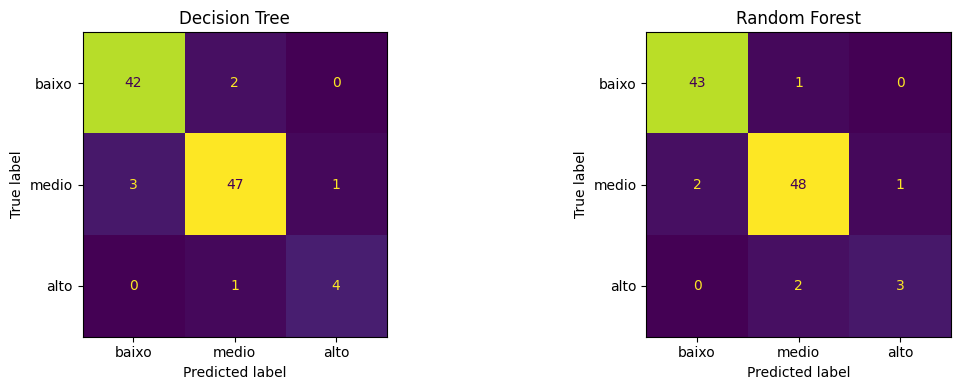

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(y_teste, pred_arvore, labels=["baixo", "medio", "alto"], ax=axes[0], colorbar=False)
axes[0].set_title("Decision Tree")
ConfusionMatrixDisplay.from_predictions(y_teste, pred_floresta, labels=["baixo", "medio", "alto"], ax=axes[1], colorbar=False)
axes[1].set_title("Random Forest")
plt.tight_layout()
plt.show()

### Leitura das matrizes de confusão e da comparação
- **Nenhum dos dois modelos confundiu `baixo` com `alto`** (nem o contrário). Todos os erros foram entre classes adjacentes (`baixo`↔`medio` e `medio`↔`alto`). Isso é esperado: engajamento é uma escala contínua que foi dividida em três faixas, então os casos próximos dos limites são os difíceis.
- A Random Forest errou 6 usuários e a Decision Tree, 7. Mesmo assim, o F1 macro da árvore ficou maior (0,8915 contra 0,8580), porque a diferença está quase toda na classe `alto` (F1 0,80 contra 0,67). Essa diferença equivale a **um único usuário `alto`** (4 acertos contra 3).
- Conclusão parcial: no conjunto de teste os dois modelos têm desempenho muito parecido; a diferença observada é pequena demais, com 5 exemplos de `alto`, para declarar um vencedor.

## 7. Validação cruzada
Como complemento ao conjunto de teste, será realizada validação cruzada estratificada de 5 partes no conjunto de treinamento, utilizando F1 macro. Isso permite observar a estabilidade média sem usar o conjunto de teste no ajuste.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for nome, modelo in [("Decision Tree", arvore), ("Random Forest", floresta)]:
    resultado = cross_validate(modelo, X_treino, y_treino, cv=cv, scoring="f1_macro", n_jobs=-1)
    print(nome, "F1 macro médio:", round(resultado["test_score"].mean(), 4),
          "| desvio padrão:", round(resultado["test_score"].std(), 4))
    print("   F1 macro por fold:", np.round(resultado["test_score"], 3))

Decision Tree F1 macro médio: 0.7895 | desvio padrão: 0.0528
   F1 macro por fold: [0.755 0.772 0.823 0.873 0.724]


Random Forest F1 macro médio: 0.8535 | desvio padrão: 0.0721
   F1 macro por fold: [0.765 0.879 0.931 0.922 0.771]


### Leitura da validação cruzada
Na validação cruzada (5 partes, apenas no treino) o resultado foi **o oposto do teste**: a Random Forest obteve F1 macro médio de 0,8535 contra 0,7895 da Decision Tree, e foi melhor nas cinco partes. Há dois cuidados na leitura: (1) o desvio padrão é alto nos dois modelos (0,05 a 0,07), já que cada parte de validação tem em média apenas cerca de 4 usuários `alto`; (2) mesmo assim, a vantagem consistente da floresta indica que a árvore tende a ser menos estável. Os dois resultados (teste e validação cruzada) precisam ser considerados juntos: **o desempenho dos modelos é parecido, e nenhum deles é claramente superior**.

## 8. Importância das variáveis e interpretação
A importância indica quais atributos mais contribuíram para as divisões da Random Forest (modelo usado nesta análise de importância). Ela não prova causalidade nem significa que alterar uma variável isoladamente causará mudança no engajamento.

,Importância
pontos,0.264684
acessos,0.146955
dias_ativo,0.127306
interacoes_chatbot,0.091480
missoes_concluidas,0.075677
recompensas_resgatadas,0.069181
acoes_sustentaveis,0.060723
streak_maximo,0.055352
participacoes_comunidade,0.027911
missoes_recebidas,0.025618


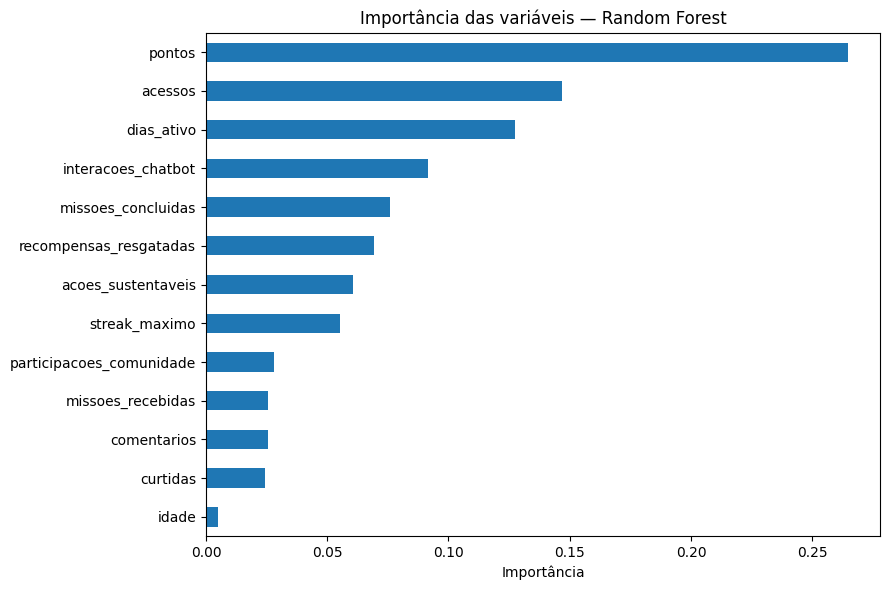

In [11]:
importancias = pd.Series(floresta.feature_importances_, index=FEATURES).sort_values(ascending=False)
display(importancias.to_frame("Importância"))
importancias.sort_values().plot(kind="barh", figsize=(9, 6), title="Importância das variáveis — Random Forest")
plt.xlabel("Importância")
plt.tight_layout()
plt.show()

### Leitura da importância das variáveis (Random Forest)
`pontos` (≈ 0,26), `acessos` (≈ 0,15), `dias_ativo` (≈ 0,13) e `interacoes_chatbot` (≈ 0,09) lideram. Variáveis como `participacoes_comunidade`, `missoes_recebidas`, `comentarios`, `curtidas` e `idade` tiveram importância baixa (≤ 0,03). Na árvore a importância é bem mais concentrada (`pontos` e `acessos` somam ≈ 89%), enquanto a floresta distribui o peso entre mais variáveis. **Cuidado:** como a base é sintética e os rótulos foram definidos por regras da equipe, essa importância provavelmente reflete as regras usadas na geração dos dados, e não o comportamento de usuários reais.

## 9. Discussão dos resultados, limitações e próximos passos

### O que deu certo
- Os dois modelos tiveram acurácia acima de 93% no teste e F1 de 0,93 ou mais nas duas classes grandes (`baixo` e `medio`).
- Nenhum modelo confundiu `baixo` com `alto`: todos os erros foram entre faixas vizinhas, o que é um comportamento razoável para uma escala de engajamento.
- A preparação foi feita com cuidado: validações de qualidade da base, divisão estratificada, uso de `class_weight` para a classe minoritária, métricas macro e validação cruzada sem tocar no conjunto de teste.
- O modelo escolhido foi serializado e está sendo servido por uma API que responde corretamente a requisições reais.

### O que não deu tão certo
- **A classe `alto` é difícil de avaliar:** são 24 registros em 500 (4,8%) e apenas 5 no teste. Recall de 0,80 (árvore) e 0,60 (floresta) correspondem a 4 e 3 acertos; qualquer conclusão sobre essa classe é frágil.
- **Teste e validação cruzada discordam:** no teste a árvore tem o maior F1 macro (0,8915 contra 0,8580); na validação cruzada a floresta vence (0,8535 contra 0,7895) nas cinco partes.
- **A árvore parece ter se ajustado a ruído** em ao menos uma folha, que usa `idade` para separar `medio` de `alto`.
- Os valores de desvio padrão da validação cruzada (0,05 a 0,07) mostram que as métricas variam bastante conforme a amostra.

### Escolha do modelo disponibilizado na API: Decision Tree
A Decision Tree foi escolhida, mas é importante ser claro sobre o motivo. **Não é possível afirmar que ela tenha desempenho superior:** a vantagem de F1 no teste equivale a um único usuário `alto`, e a validação cruzada favorece a Random Forest. A escolha se apoia, portanto, em **interpretabilidade e simplicidade**: as regras da árvore podem ser lidas e explicadas (por exemplo, `alto` exige muitos pontos e muita interação com o chatbot), o que é importante para justificar sugestões ao usuário, e o arquivo do modelo é pequeno e leve para a API. O custo dessa decisão é possivelmente menor estabilidade. Se o objetivo do produto passar a ser maximizar o desempenho, a Random Forest é a candidata natural: a API usa apenas o objeto `model` e a lista `features` do arquivo `.joblib`, então a troca exige só salvar o outro modelo no mesmo formato.

### Limitações
1. Os 500 registros são sintéticos e foram gerados por regras definidas pela equipe.
2. O alvo pode refletir essas mesmas regras; o modelo pode estar aprendendo a simulação, e não comportamento humano.
3. Há forte desequilíbrio entre classes (`alto` com 4,8%).
4. O conjunto de teste é pequeno (100 registros, 5 de `alto`), e a escolha entre modelos foi feita olhando para ele; as diferenças observadas estão dentro da margem de ruído.
5. Resultados em dados simulados não garantem generalização para usuários reais.
6. A importância das variáveis não demonstra causalidade.
7. As probabilidades da árvore são frequentemente 0 ou 1 (folhas puras) e não devem ser lidas como grau de confiança calibrado.

### Próximos passos
- Coletar dados reais, com consentimento e governança, e revisar a definição dos rótulos.
- Aumentar o número de exemplos da classe `alto` e repetir a avaliação com validação cruzada repetida, para uma comparação mais estável entre os modelos.
- Ajustar hiperparâmetros (por exemplo, com busca em grade usando a validação cruzada) e, se necessário, limitar o uso de variáveis de perfil, como `idade`, no treinamento.
- Calibrar as probabilidades antes de usá-las como indicador de confiança.
- Monitorar o modelo após a entrada em produção.

### Aplicação no SoulIA
A previsão pode apoiar mensagens e sugestões de missões mais adequadas ao perfil de atividade. A recomendação deve ser apresentada como sugestão, e não como julgamento do usuário.

## 10. Serialização do modelo para a API
Salvamos o modelo Decision Tree junto com a lista e a ordem das variáveis esperadas pela API.

In [12]:
artefato = {"model": arvore, "features": FEATURES, "classes": list(arvore.classes_), "model_name": "DecisionTreeClassifier"}
joblib.dump(artefato, "soulia_decision_tree.joblib")
print("Modelo salvo em soulia_decision_tree.joblib")

Modelo salvo em soulia_decision_tree.joblib
